# 03 · Modelado

XGBoost y regresión logística ponderadas, evaluación, bootstrap por UPM y SHAP. Usa `base_modelado.pkl` del notebook 01.

## 1. Carga y división de la base

In [1]:
import pandas as pd

df = pd.read_pickle("base_modelado.pkl")
print(df.shape)

# Cuántos registros hay por mes
print(df["periodo"].value_counts().sort_index())

# ¿Se repite algún id_persona?
print("Personas únicas:", df["id_persona"].nunique())
print("Registros con id repetido:", df["id_persona"].duplicated(keep=False).sum())

(19525, 22)
periodo
202501.0    1616
202502.0    1632
202503.0    1621
202504.0    1663
202505.0    1661
202506.0    1659
202507.0    1584
202508.0    1696
202509.0    1599
202510.0    1553
202511.0    1674
202512.0    1567
Name: count, dtype: int64
Personas únicas: 19525
Registros con id repetido: 0


In [2]:
print(df[["id_persona", "periodo", "upm"]].head(10))
print(df["id_persona"].astype(str).str.len().value_counts())

                    id_persona   periodo           upm
115994  0901500001010660110108  202508.0  090150000101
115995  0901500001010660110208  202508.0  090150000101
115996  0901500001010660110308  202508.0  090150000101
115999  0901500001010660210205  202505.0  090150000101
116000  0901500001010660210305  202505.0  090150000101
116004  0901500001010660210208  202508.0  090150000101
116005  0901500001010660210308  202508.0  090150000101
116008  0901500001010660310105  202505.0  090150000101
116010  0901500001010660310305  202505.0  090150000101
116011  0901500001010660310405  202505.0  090150000101
id_persona
22    19525
Name: count, dtype: int64


In [3]:
df["id_sin_mes"] = df["id_persona"].astype(str).str[:-2]

print("Personas reales:", df["id_sin_mes"].nunique())
print(df.groupby("id_sin_mes").size().value_counts().sort_index())

Personas reales: 13555
1    7585
2    5970
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(gss.split(df, groups=df["upm"]))

train = df.iloc[idx_train]
test = df.iloc[idx_test]

print("Entrenamiento:", train.shape, "| UPM:", train["upm"].nunique())
print("Prueba:", test.shape, "| UPM:", test["upm"].nunique())

Entrenamiento: (15814, 23) | UPM: 754
Prueba: (3711, 23) | UPM: 189


In [5]:
import numpy as np

print("UPM compartidas:", len(set(train["upm"]) & set(test["upm"])))
print("Personas compartidas:", len(set(train["id_sin_mes"]) & set(test["id_sin_mes"])))

for nombre, parte in [("Entrenamiento", train), ("Prueba", test)]:
    tasa = np.average(parte["y"], weights=parte["fexp"])
    print(nombre, "- tasa ponderada:", round(tasa * 100, 1), "%")

UPM compartidas: 0
Personas compartidas: 0
Entrenamiento - tasa ponderada: 41.5 %
Prueba - tasa ponderada: 41.7 %


## 2. Codificación de variables

In [6]:
predictoras = ["p02", "p03", "p06", "p15aa", "p07",
               "parentesco", "etnia", "instruccion", "zona_amp",
               "anios_esc", "tit_nivel", "tit_campo",
               "tam_hogar", "menores5", "mayores65"]

print(df[predictoras].dtypes)

p02            float64
p03            float64
p06            float64
p15aa          float64
p07            float64
parentesco         str
etnia              str
instruccion        str
zona_amp           str
anios_esc      float64
tit_nivel          str
tit_campo          str
tam_hogar        int64
menores5         int64
mayores65        int64
dtype: object


In [7]:
for v in ["p02", "p06", "p15aa", "p07"]:
    print(df[v].value_counts(dropna=False).sort_index(), "\n")

p02
1.0    11835
2.0     7690
Name: count, dtype: int64 

p06
1.0    4756
2.0    3249
3.0     541
4.0     536
5.0    4970
6.0    5473
Name: count, dtype: int64 

p15aa
1.0    12861
2.0     6257
3.0      407
Name: count, dtype: int64 

p07
1.0     1066
2.0    18459
Name: count, dtype: int64 



In [8]:
texto = ["parentesco", "etnia", "instruccion", "zona_amp", "tit_nivel", "tit_campo"]

for v in texto:
    print(df[v].value_counts(dropna=False), "\n")

print(pd.crosstab(df["instruccion"], df["tit_nivel"]))

parentesco
Jefe       8752
Hijo/a     5441
Cónyuge    3021
Otros      2311
Name: count, dtype: int64 

etnia
Mestizo             18208
Montuvio              565
Afrodescendiente      434
Otros                 318
Name: count, dtype: int64 

instruccion
Media/Bachillerato     8269
Básica                 5335
Superior con título    3929
Superior sin título    1744
Ninguno                 248
Name: count, dtype: int64 

zona_amp
Guayaquil       16147
Conurbación      1293
Resto urbano     1080
Resto rural      1005
Name: count, dtype: int64 

tit_nivel
Sin título superior    15596
Grado                   2769
Tecnológico              544
Postgrado                501
Técnico                  115
Name: count, dtype: int64 

tit_campo
Sin título superior            15596
Administración                  1028
Educación                        673
Ciencias sociales y derecho      568
Ingeniería                       520
Salud                            394
TIC                              256
Se

In [9]:
# --- Bloque 1: tabla vacía y numéricas tal cual ---
X = pd.DataFrame(index=df.index)

for v in ["p03", "anios_esc", "tam_hogar", "menores5", "mayores65"]:
    X[v] = df[v]

# --- Bloque 2: binarias a 0/1 ---
X["mujer"] = (df["p02"] == 2).astype(int)
X["asiste_clases"] = (df["p07"] == 1).astype(int)

# --- Bloque 3: etiquetas legibles para p06 y p15aa ---
estado_civil = {1: "casado", 2: "separado", 3: "divorciado",
                4: "viudo", 5: "union_libre", 6: "soltero"}
nacimiento = {1: "misma_ciudad", 2: "otro_lugar_pais", 3: "otro_pais"}

# --- Bloque 4: función que crea indicadoras y quita la referencia ---
def indicadoras(serie, nombre, referencia, excluir=[]):
    d = pd.get_dummies(serie, prefix=nombre, dtype=int)
    quitar = [nombre + "_" + c for c in [referencia] + excluir]
    return d.drop(columns=quitar)

# --- Bloque 5: aplicar a cada categórica ---
partes = [
    indicadoras(df["p06"].map(estado_civil), "p06", "soltero"),
    indicadoras(df["p15aa"].map(nacimiento), "p15aa", "misma_ciudad"),
    indicadoras(df["parentesco"], "parentesco", "Jefe"),
    indicadoras(df["etnia"], "etnia", "Mestizo"),
    indicadoras(df["instruccion"], "instruccion", "Media/Bachillerato",
                excluir=["Superior con título"]),
    indicadoras(df["zona_amp"], "zona_amp", "Guayaquil"),
    indicadoras(df["tit_nivel"], "tit_nivel", "Sin título superior"),
    indicadoras(df["tit_campo"], "tit_campo", "Administración",
                excluir=["Sin título superior"]),
]

X = pd.concat([X] + partes, axis=1)

# --- Bloque 6: controles ---
print(X.shape)
print("Vacíos:", X.isna().sum().sum())
print(X.columns.tolist())

(19525, 38)
Vacíos: 0
['p03', 'anios_esc', 'tam_hogar', 'menores5', 'mayores65', 'mujer', 'asiste_clases', 'p06_casado', 'p06_divorciado', 'p06_separado', 'p06_union_libre', 'p06_viudo', 'p15aa_otro_lugar_pais', 'p15aa_otro_pais', 'parentesco_Cónyuge', 'parentesco_Hijo/a', 'parentesco_Otros', 'etnia_Afrodescendiente', 'etnia_Montuvio', 'etnia_Otros', 'instruccion_Básica', 'instruccion_Ninguno', 'instruccion_Superior sin título', 'zona_amp_Conurbación', 'zona_amp_Resto rural', 'zona_amp_Resto urbano', 'tit_nivel_Grado', 'tit_nivel_Postgrado', 'tit_nivel_Tecnológico', 'tit_nivel_Técnico', 'tit_campo_Artes y humanidades', 'tit_campo_Ciencias sociales y derecho', 'tit_campo_Educación', 'tit_campo_Ingeniería', 'tit_campo_Otros campos', 'tit_campo_Salud', 'tit_campo_Servicios', 'tit_campo_TIC']


anios_esc  instruccion_Básica   -0.764
tam_hogar  menores5              0.667
anios_esc  tit_nivel_Grado       0.504
dtype: float64


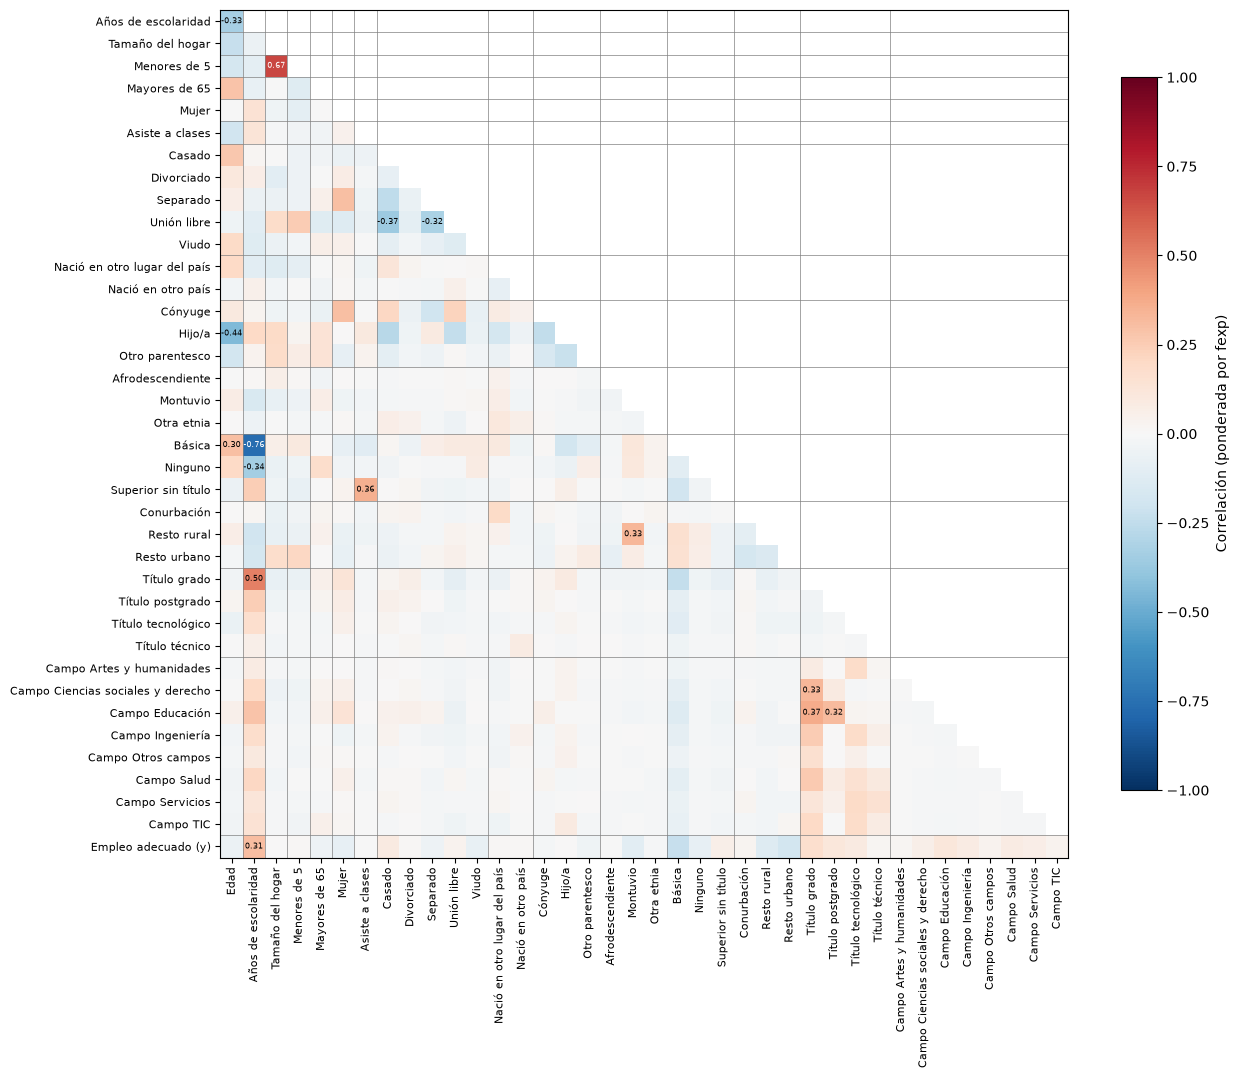

In [10]:
import matplotlib.pyplot as plt

# Correlación ponderada por fexp: 38 columnas del modelo y la variable objetivo
M = X.assign(y=df["y"]).astype(float)
corr = pd.DataFrame(np.cov(M.T, aweights=df["fexp"]), index=M.columns, columns=M.columns)
desv = np.sqrt(np.diag(corr))
corr = corr / np.outer(desv, desv)
corr.round(3).to_csv("matriz_correlacion.csv", encoding="utf-8-sig")

# Pares con correlación de 0,5 o más (en valor absoluto)
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pares[pares.abs() >= 0.5].sort_values(key=lambda s: s.abs(), ascending=False).round(3))


nombres = {"p03": "Edad", "anios_esc": "Años de escolaridad", "tam_hogar": "Tamaño del hogar",
           "menores5": "Menores de 5", "mayores65": "Mayores de 65", "mujer": "Mujer",
           "asiste_clases": "Asiste a clases", "p06_union_libre": "Unión libre",
           "p15aa_otro_lugar_pais": "Nació en otro lugar del país", "p15aa_otro_pais": "Nació en otro país",
           "parentesco_Otros": "Otro parentesco", "etnia_Otros": "Otra etnia", "y": "Empleo adecuado (y)"}

def etiqueta(c):
    if c in nombres:
        return nombres[c]
    resto = c.split("_")[-1]
    if c.startswith("p06_"):
        return resto.capitalize()
    if c.startswith("tit_nivel_"):
        return "Título " + resto.lower()
    if c.startswith("tit_campo_"):
        return "Campo " + resto
    return resto

def grupo(c):
    for v in ["p06", "p15aa", "parentesco", "etnia", "instruccion", "zona_amp", "tit_nivel", "tit_campo"]:
        if c.startswith(v + "_"):
            return v
    return c

tri = corr.mask(np.triu(np.ones(corr.shape, dtype=bool))).iloc[1:, :-1]
filas, cols = tri.index, tri.columns

fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(tri, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([etiqueta(c) for c in cols], rotation=90, fontsize=8)
ax.set_yticks(range(len(filas)))
ax.set_yticklabels([etiqueta(c) for c in filas], fontsize=8)

# Valores solo donde la correlación es apreciable
for i in range(len(filas)):
    for j in range(len(cols)):
        r = tri.iloc[i, j]
        if pd.notna(r) and abs(r) >= 0.3:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(r) >= 0.6 else "black")

for k in range(1, len(cols)):
    if grupo(cols[k]) != grupo(cols[k - 1]):
        ax.axvline(k - 0.5, color="gray", linewidth=0.5)
for k in range(1, len(filas)):
    if grupo(filas[k]) != grupo(filas[k - 1]):
        ax.axhline(k - 0.5, color="gray", linewidth=0.5)

fig.colorbar(im, ax=ax, shrink=0.7, label="Correlación (ponderada por fexp)")
plt.tight_layout()
plt.savefig("matriz_correlacion.png", dpi=300)
plt.show()

In [11]:
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = df["y"].iloc[idx_train], df["y"].iloc[idx_test]
w_train, w_test = df["fexp"].iloc[idx_train], df["fexp"].iloc[idx_test]

print(X_train.shape, y_train.shape, w_train.shape)
print(X_test.shape, y_test.shape, w_test.shape)

(15814, 38) (15814,) (15814,)
(3711, 38) (3711,) (3711,)


## 3. Primeros modelos

In [12]:
import xgboost
import shap

print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

XGBoost: 3.4.1
SHAP: 0.54.1


In [13]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

# Pesos normalizados: mismas proporciones, promedio 1
w_train_n = w_train / w_train.mean()

modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
)
modelo_xgb.fit(X_train, y_train, sample_weight=w_train_n)

# Evaluación rápida en prueba
prob_test = modelo_xgb.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, prob_test, sample_weight=w_test)
print("AUC ponderado en prueba:", round(auc, 3))

AUC ponderado en prueba: 0.761


In [14]:
from sklearn.linear_model import LogisticRegression

modelo_log = LogisticRegression(C=1e6, max_iter=5000)
modelo_log.fit(X_train, y_train, sample_weight=w_train_n)

prob_test_log = modelo_log.predict_proba(X_test)[:, 1]
auc_log = roc_auc_score(y_test, prob_test_log, sample_weight=w_test)
print("AUC ponderado logística:", round(auc_log, 3))

AUC ponderado logística: 0.751


## 4. Afinamiento y robustez

In [15]:
import numpy as np
from sklearn.model_selection import GroupKFold, ParameterSampler
from scipy.stats import randint, uniform, loguniform

# --- Bloque 1: las 5 partes, separando por UPM ---
grupos_train = df["upm"].iloc[idx_train]
gkf = GroupKFold(n_splits=5)
partes_cv = list(gkf.split(X_train, y_train, groups=grupos_train))

# --- Bloque 2: rangos de búsqueda y sorteo de 40 combinaciones ---
espacio = {
    "n_estimators": randint(200, 801),
    "max_depth": randint(2, 7),
    "learning_rate": loguniform(0.01, 0.1),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
}
combinaciones = list(ParameterSampler(espacio, n_iter=40, random_state=42))

# --- Bloque 3: probar cada combinación en las 5 partes ---
import os

archivo = "afinamiento_xgb_parcial.csv"
if os.path.exists(archivo):
    resultados = pd.read_csv(archivo).to_dict("records")
else:
    resultados = []
hechas = len(resultados)
print("Combinaciones ya guardadas:", hechas)

for i, params in enumerate(combinaciones, start=1):
    if i <= hechas:
        continue
    aucs = []
    for idx_fit, idx_val in partes_cv:
        m = XGBClassifier(**params, random_state=42)
        m.fit(X_train.iloc[idx_fit], y_train.iloc[idx_fit],
              sample_weight=w_train_n.iloc[idx_fit])
        p = m.predict_proba(X_train.iloc[idx_val])[:, 1]
        aucs.append(roc_auc_score(y_train.iloc[idx_val], p,
                                  sample_weight=w_train.iloc[idx_val]))
    resultados.append({**params, "auc_cv": np.mean(aucs), "auc_sd": np.std(aucs)})
    pd.DataFrame(resultados).to_csv(archivo, index=False)
    print(f"{i}/40  AUC = {np.mean(aucs):.4f}")

Combinaciones ya guardadas: 0
1/40  AUC = 0.7213
2/40  AUC = 0.7335
3/40  AUC = 0.7217
4/40  AUC = 0.7249
5/40  AUC = 0.7304
6/40  AUC = 0.7202
7/40  AUC = 0.7250
8/40  AUC = 0.7285
9/40  AUC = 0.7215
10/40  AUC = 0.7208
11/40  AUC = 0.7086
12/40  AUC = 0.7295
13/40  AUC = 0.7213
14/40  AUC = 0.7302
15/40  AUC = 0.7270
16/40  AUC = 0.7265
17/40  AUC = 0.7217
18/40  AUC = 0.7315
19/40  AUC = 0.7248
20/40  AUC = 0.7201
21/40  AUC = 0.7299
22/40  AUC = 0.7233
23/40  AUC = 0.7267
24/40  AUC = 0.7275
25/40  AUC = 0.7255
26/40  AUC = 0.7267
27/40  AUC = 0.7257
28/40  AUC = 0.7219
29/40  AUC = 0.7270
30/40  AUC = 0.7105
31/40  AUC = 0.7241
32/40  AUC = 0.7196
33/40  AUC = 0.7264
34/40  AUC = 0.7280
35/40  AUC = 0.7279
36/40  AUC = 0.7100
37/40  AUC = 0.7311
38/40  AUC = 0.7212
39/40  AUC = 0.7260
40/40  AUC = 0.7268


In [16]:
tabla_cv = pd.DataFrame(resultados).sort_values("auc_cv", ascending=False)
tabla_cv.to_csv("afinamiento_xgb.csv", index=False)
print(tabla_cv.head(5))

    colsample_bytree  learning_rate  max_depth  min_child_weight  \
1           0.662398       0.011431          6                 4   
17          0.888692       0.017218          4                 9   
36          0.735612       0.022347          4                 4   
4           0.693109       0.012320          4                 7   
13          0.679486       0.010128          4                 3   

    n_estimators  subsample    auc_cv    auc_sd  
1            330   0.608234  0.733470  0.022387  
17           406   0.771016  0.731495  0.022178  
36           351   0.761803  0.731073  0.020741  
4            443   0.836966  0.730366  0.025309  
13           792   0.884537  0.730177  0.021544  


In [17]:
from sklearn.linear_model import LogisticRegression

# Ajustes de la mejor combinación
mejores = tabla_cv.iloc[0].drop(["auc_cv", "auc_sd"]).to_dict()
for k in ["n_estimators", "max_depth", "min_child_weight"]:
    mejores[k] = int(mejores[k])
print(mejores)

# Los tres modelos en las mismas 5 partes
auc_log, auc_base, auc_afin = [], [], []

for idx_fit, idx_val in partes_cv:
    Xf, yf, wf = X_train.iloc[idx_fit], y_train.iloc[idx_fit], w_train_n.iloc[idx_fit]
    Xv, yv, wv = X_train.iloc[idx_val], y_train.iloc[idx_val], w_train.iloc[idx_val]

    lg = LogisticRegression(C=1e6, max_iter=5000).fit(Xf, yf, sample_weight=wf)
    auc_log.append(roc_auc_score(yv, lg.predict_proba(Xv)[:, 1], sample_weight=wv))

    bs = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                       random_state=42).fit(Xf, yf, sample_weight=wf)
    auc_base.append(roc_auc_score(yv, bs.predict_proba(Xv)[:, 1], sample_weight=wv))

    af = XGBClassifier(**mejores, random_state=42).fit(Xf, yf, sample_weight=wf)
    auc_afin.append(roc_auc_score(yv, af.predict_proba(Xv)[:, 1], sample_weight=wv))

comp = pd.DataFrame({"logistica": auc_log, "xgb_base": auc_base, "xgb_afinado": auc_afin})
print(comp.round(4))
print("\nPromedio:\n", comp.mean().round(4))

{'colsample_bytree': 0.662397808134481, 'learning_rate': 0.011430983876313222, 'max_depth': 6, 'min_child_weight': 4, 'n_estimators': 330, 'subsample': 0.608233797718321}
   logistica  xgb_base  xgb_afinado
0     0.7432    0.6893       0.6934
1     0.7220    0.7452       0.7516
2     0.7147    0.7273       0.7374
3     0.6994    0.7244       0.7285
4     0.7281    0.7478       0.7565

Promedio:
 logistica      0.7215
xgb_base       0.7268
xgb_afinado    0.7335
dtype: float64


In [18]:
val_base = df.iloc[idx_train]

for k, (idx_fit, idx_val) in enumerate(partes_cv):
    val = val_base.iloc[idx_val]
    tasa = np.average(val["y"], weights=val["fexp"])
    print(f"Parte {k}: UPM={val['upm'].nunique()}, filas={len(val)}, tasa={tasa*100:.1f} %")
    print("   ", val["zona_amp"].value_counts(normalize=True).round(3).to_dict())

Parte 0: UPM=150, filas=3162, tasa=35.3 %
    {'Guayaquil': 0.839, 'Resto urbano': 0.064, 'Conurbación': 0.056, 'Resto rural': 0.041}
Parte 1: UPM=151, filas=3164, tasa=43.6 %
    {'Guayaquil': 0.875, 'Conurbación': 0.072, 'Resto rural': 0.041, 'Resto urbano': 0.011}
Parte 2: UPM=151, filas=3163, tasa=44.0 %
    {'Guayaquil': 0.807, 'Conurbación': 0.08, 'Resto urbano': 0.08, 'Resto rural': 0.033}
Parte 3: UPM=151, filas=3163, tasa=44.6 %
    {'Guayaquil': 0.788, 'Conurbación': 0.078, 'Resto urbano': 0.071, 'Resto rural': 0.063}
Parte 4: UPM=151, filas=3162, tasa=40.8 %
    {'Guayaquil': 0.794, 'Resto rural': 0.082, 'Conurbación': 0.068, 'Resto urbano': 0.057}


In [19]:
filas = []

for k, (idx_fit, idx_val) in enumerate(partes_cv):
    val = val_base.iloc[idx_val]
    w = val["fexp"]
    filas.append({
        "parte": k,
        "tasa_y": np.average(val["y"], weights=w),
        "anios_esc": np.average(val["anios_esc"], weights=w),
        "con_titulo": np.average(val["tit_nivel"] != "Sin título superior", weights=w),
        "mujer": np.average(val["p02"] == 2, weights=w),
        "edad": np.average(val["p03"], weights=w),
    })

print(pd.DataFrame(filas).round(3))

   parte  tasa_y  anios_esc  con_titulo  mujer    edad
0      0   0.353      9.333       0.097  0.283  40.589
1      1   0.436     10.572       0.125  0.392  40.243
2      2   0.440     10.753       0.141  0.390  40.694
3      3   0.446     10.708       0.139  0.376  40.600
4      4   0.408     10.321       0.120  0.360  40.702


In [20]:
from sklearn.model_selection import GroupShuffleSplit

gss_rep = GroupShuffleSplit(n_splits=25, test_size=0.2, random_state=42)
filas_rep = []

for k, (idx_fit, idx_val) in enumerate(
        gss_rep.split(X_train, y_train, groups=grupos_train), start=1):
    Xf, yf, wf = X_train.iloc[idx_fit], y_train.iloc[idx_fit], w_train_n.iloc[idx_fit]
    Xv, yv, wv = X_train.iloc[idx_val], y_train.iloc[idx_val], w_train.iloc[idx_val]

    lg = LogisticRegression(C=1e6, max_iter=5000).fit(Xf, yf, sample_weight=wf)
    af = XGBClassifier(**mejores, random_state=42).fit(Xf, yf, sample_weight=wf)

    a_log = roc_auc_score(yv, lg.predict_proba(Xv)[:, 1], sample_weight=wv)
    a_xgb = roc_auc_score(yv, af.predict_proba(Xv)[:, 1], sample_weight=wv)

    filas_rep.append({"sorteo": k, "auc_log": a_log, "auc_xgb": a_xgb,
                      "anios_esc_val": np.average(Xv["anios_esc"], weights=wv)})
    print(f"{k}/25  log={a_log:.4f}  xgb={a_xgb:.4f}")

rep = pd.DataFrame(filas_rep)
rep["ganancia"] = rep["auc_xgb"] - rep["auc_log"]
rep.to_csv("comparacion_25_sorteos.csv", index=False)

print("\nXGBoost gana en", (rep["ganancia"] > 0).sum(), "de 25 sorteos")
print("Ganancia promedio:", round(rep["ganancia"].mean(), 4))
print("Correlación ganancia–escolaridad:",
      round(rep["ganancia"].corr(rep["anios_esc_val"]), 3))

1/25  log=0.7170  xgb=0.7337
2/25  log=0.7034  xgb=0.7458
3/25  log=0.7272  xgb=0.7471
4/25  log=0.7102  xgb=0.7394
5/25  log=0.7048  xgb=0.7271
6/25  log=0.7106  xgb=0.7320
7/25  log=0.7039  xgb=0.7469
8/25  log=0.7324  xgb=0.7137
9/25  log=0.7323  xgb=0.7465
10/25  log=0.7043  xgb=0.7336
11/25  log=0.7250  xgb=0.7283
12/25  log=0.7091  xgb=0.6869
13/25  log=0.7192  xgb=0.7405
14/25  log=0.7034  xgb=0.7341
15/25  log=0.7458  xgb=0.7695
16/25  log=0.7269  xgb=0.6931
17/25  log=0.7098  xgb=0.7467
18/25  log=0.7042  xgb=0.7460
19/25  log=0.7144  xgb=0.7433
20/25  log=0.7384  xgb=0.7529
21/25  log=0.7092  xgb=0.7353
22/25  log=0.7531  xgb=0.7770
23/25  log=0.7518  xgb=0.7755
24/25  log=0.7348  xgb=0.7568
25/25  log=0.6980  xgb=0.7176

XGBoost gana en 22 de 25 sorteos
Ganancia promedio: 0.0192
Correlación ganancia–escolaridad: 0.748


## 5. Evaluación final en prueba

In [21]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Hiperparámetros ganadores del afinamiento
mejores = {
    "max_depth": 6,
    "n_estimators": 330,
    "learning_rate": 0.0114,
    "min_child_weight": 4,
    "subsample": 0.61,
    "colsample_bytree": 0.66,
}

modelo_xgb_final = XGBClassifier(**mejores, random_state=42, n_jobs=-1)
modelo_xgb_final.fit(X_train, y_train, sample_weight=w_train_n)

modelo_log_final = LogisticRegression(C=1e6, max_iter=5000)
modelo_log_final.fit(X_train, y_train, sample_weight=w_train_n)

# Riesgo = 1 - probabilidad de empleo adecuado
riesgo_xgb = 1 - modelo_xgb_final.predict_proba(X_test)[:, 1]
riesgo_log = 1 - modelo_log_final.predict_proba(X_test)[:, 1]
y_riesgo = 1 - y_test

print("AUC XGBoost:  ", round(roc_auc_score(y_riesgo, riesgo_xgb, sample_weight=w_test), 3))
print("AUC logística:", round(roc_auc_score(y_riesgo, riesgo_log, sample_weight=w_test), 3))

AUC XGBoost:   0.767
AUC logística: 0.751


In [22]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

def precision_decil(y_r, riesgo, w, frac=0.10):
    # Ordena de mayor a menor riesgo y toma el 10 % de la POBLACIÓN (según pesos)
    orden = np.argsort(-riesgo)
    w_ord = np.asarray(w)[orden]
    y_ord = np.asarray(y_r)[orden]
    acum = np.cumsum(w_ord) / w_ord.sum()
    dentro = (acum - w_ord / w_ord.sum()) < frac
    return np.average(y_ord[dentro], weights=w_ord[dentro])

def metricas(riesgo):
    pred = (riesgo >= 0.5).astype(int)
    return {
        "AUC": roc_auc_score(y_riesgo, riesgo, sample_weight=w_test),
        "Precision": precision_score(y_riesgo, pred, sample_weight=w_test),
        "Recall": recall_score(y_riesgo, pred, sample_weight=w_test),
        "F1": f1_score(y_riesgo, pred, sample_weight=w_test),
        "Prec. decil superior": precision_decil(y_riesgo, riesgo, w_test),
    }

tabla = pd.DataFrame({
    "XGBoost": metricas(riesgo_xgb),
    "Logística": metricas(riesgo_log),
}).round(3)

prevalencia = np.average(y_riesgo, weights=w_test)

print(tabla)
print("\nPrevalencia ponderada del riesgo en prueba:", round(prevalencia, 3))

tabla.to_csv("metricas_prueba.csv")

                      XGBoost  Logística
AUC                     0.767      0.751
Precision               0.726      0.718
Recall                  0.765      0.802
F1                      0.745      0.758
Prec. decil superior    0.923      0.940

Prevalencia ponderada del riesgo en prueba: 0.583


In [23]:
base = pd.read_pickle("base_modelado.pkl")

# Verificación: las filas de prueba de la base coinciden con y_test
print("Orden correcto:", (base["y"].iloc[idx_test].values == np.asarray(y_test)).all())

educ_test = base["instruccion"].iloc[idx_test].values
orden = base.groupby("instruccion")["anios_esc"].mean().sort_values().index

def metricas_grupo(yr, r, w):
    pred = (r >= 0.5).astype(int)
    return {
        "AUC": roc_auc_score(yr, r, sample_weight=w),
        "Precision": precision_score(yr, pred, sample_weight=w, zero_division=0),
        "Recall": recall_score(yr, pred, sample_weight=w, zero_division=0),
        "F1": f1_score(yr, pred, sample_weight=w, zero_division=0),
        "Prec. decil": precision_decil(yr, r, w),
    }

filas = []
for g in orden:
    m = educ_test == g
    yr = np.asarray(y_riesgo)[m]
    w = np.asarray(w_test)[m]
    fila = {"Grupo": g, "Registros": m.sum(), "Prevalencia": np.average(yr, weights=w)}
    if yr.min() != yr.max():
        mx = metricas_grupo(yr, riesgo_xgb[m], w)
        ml = metricas_grupo(yr, riesgo_log[m], w)
        for k in mx:
            fila[f"{k} XGB"] = mx[k]
            fila[f"{k} Log"] = ml[k]
    filas.append(fila)

tabla_educ = pd.DataFrame(filas).set_index("Grupo").round(3)
print(tabla_educ.T)
tabla_educ.to_csv("metricas_por_educacion.csv")

Orden correcto: True
Grupo            Ninguno   Básica  Media/Bachillerato  Superior sin título  \
Registros         47.000  964.000            1564.000              333.000   
Prevalencia        0.955    0.764               0.541                0.428   
AUC XGB            0.600    0.711               0.705                0.591   
AUC Log            0.657    0.664               0.708                0.556   
Precision XGB      0.969    0.785               0.658                0.509   
Precision Log      0.955    0.791               0.655                0.457   
Recall XGB         0.995    0.874               0.761                0.452   
Recall Log         1.000    0.933               0.771                0.459   
F1 XGB             0.982    0.827               0.705                0.479   
F1 Log             0.977    0.857               0.709                0.458   
Prec. decil XGB    1.000    0.954               0.852                0.588   
Prec. decil Log    1.000    0.947          

In [24]:
def mascara_decil(riesgo, w, frac=0.10):
    # Marca con True a las personas del 10 % de mayor riesgo (por pesos)
    orden_r = np.argsort(-riesgo)
    w_ord = np.asarray(w)[orden_r]
    acum = np.cumsum(w_ord) / w_ord.sum()
    dentro = (acum - w_ord / w_ord.sum()) < frac
    mascara = np.zeros(len(riesgo), dtype=bool)
    mascara[orden_r[dentro]] = True
    return mascara

w_arr = np.asarray(w_test)
d_xgb = mascara_decil(riesgo_xgb, w_arr)
d_log = mascara_decil(riesgo_log, w_arr)

comp = {}
for nombre, d in [("XGBoost", d_xgb), ("Logística", d_log)]:
    s = pd.Series(w_arr[d]).groupby(educ_test[d]).sum()
    comp[nombre] = s / s.sum()
comp["Población"] = pd.Series(w_arr).groupby(educ_test).sum() / w_arr.sum()

tabla_comp = pd.DataFrame(comp).reindex(orden).fillna(0).round(3)
print(tabla_comp)

print("\nRegistros en el decil  XGBoost:", d_xgb.sum(), "| Logística:", d_log.sum())
print("Coincidencia entre los dos deciles:",
      round(w_arr[d_xgb & d_log].sum() / w_arr[d_xgb].sum(), 3))

                     XGBoost  Logística  Población
instruccion                                       
Ninguno                0.071      0.096      0.021
Básica                 0.775      0.765      0.353
Media/Bachillerato     0.153      0.132      0.424
Superior sin título    0.001      0.005      0.055
Superior con título    0.000      0.002      0.148

Registros en el decil  XGBoost: 179 | Logística: 146
Coincidencia entre los dos deciles: 0.635


In [25]:
# Qué parte de cada grupo educativo cae en el decil de mayor riesgo de XGBoost
for nombre, grupo in [("Básica", ["Básica"]), ("Básica o menos", ["Ninguno", "Básica"])]:
    m = np.isin(educ_test, grupo)
    print(nombre, round(w_arr[m & d_xgb].sum() / w_arr[m].sum(), 3))

Básica 0.227
Básica o menos 0.234


## 6. Bootstrap por UPM

In [26]:
upm_test = base["upm"].iloc[idx_test].values
yr_arr = np.asarray(y_riesgo)
w_arr = np.asarray(w_test)

# Posiciones de los registros de cada UPM
pos_por_upm = [np.where(upm_test == u)[0] for u in np.unique(upm_test)]
n_upm = len(pos_por_upm)
print("UPM en prueba:", n_upm)

rng = np.random.default_rng(42)
B = 1000
resultados = []

for b in range(B):
    elegidas = rng.integers(0, n_upm, n_upm)
    idx = np.concatenate([pos_por_upm[i] for i in elegidas])
    mx = metricas_grupo(yr_arr[idx], riesgo_xgb[idx], w_arr[idx])
    ml = metricas_grupo(yr_arr[idx], riesgo_log[idx], w_arr[idx])
    fila = {}
    for k in mx:
        fila[f"{k}|XGB"] = mx[k]
        fila[f"{k}|Log"] = ml[k]
        fila[f"{k}|Dif"] = mx[k] - ml[k]
    resultados.append(fila)
    if (b + 1) % 200 == 0:
        print("Repeticiones:", b + 1)

boot = pd.DataFrame(resultados)
boot.to_csv("bootstrap_prueba.csv", index=False)

def ic(serie):
    return f"[{serie.quantile(0.025):.3f}, {serie.quantile(0.975):.3f}]"

tabla_ic = pd.DataFrame([{
    "Métrica": k,
    "IC XGBoost": ic(boot[f"{k}|XGB"]),
    "IC Logística": ic(boot[f"{k}|Log"]),
    "IC Diferencia": ic(boot[f"{k}|Dif"]),
    "% XGB gana": round((boot[f"{k}|Dif"] > 0).mean() * 100, 1),
} for k in ["AUC", "Precision", "Recall", "F1", "Prec. decil"]]).set_index("Métrica")

print(tabla_ic)

UPM en prueba: 189
Repeticiones: 200
Repeticiones: 400
Repeticiones: 600
Repeticiones: 800
Repeticiones: 1000
                 IC XGBoost    IC Logística     IC Diferencia  % XGB gana
Métrica                                                                  
AUC          [0.726, 0.801]  [0.710, 0.786]    [0.002, 0.029]        99.6
Precision    [0.665, 0.782]  [0.657, 0.771]   [-0.008, 0.023]        86.5
Recall       [0.698, 0.816]  [0.740, 0.853]  [-0.059, -0.017]         0.0
F1           [0.685, 0.795]  [0.700, 0.806]   [-0.028, 0.001]         3.8
Prec. decil  [0.845, 0.966]  [0.759, 0.984]   [-0.060, 0.146]        46.3


In [27]:
grupos_b = ["Básica", "Media/Bachillerato", "Superior con título"]
rng = np.random.default_rng(42)
res_g = []

for b in range(B):
    elegidas = rng.integers(0, n_upm, n_upm)
    idx = np.concatenate([pos_por_upm[i] for i in elegidas])
    e = educ_test[idx]
    fila = {}
    for g in grupos_b:
        sub = idx[e == g]
        yr, w = yr_arr[sub], w_arr[sub]
        for nombre, r in [("XGB", riesgo_xgb), ("Log", riesgo_log)]:
            fila[f"{g}|AUC|{nombre}"] = roc_auc_score(yr, r[sub], sample_weight=w)
            fila[f"{g}|Decil|{nombre}"] = precision_decil(yr, r[sub], w)
    res_g.append(fila)
    if (b + 1) % 200 == 0:
        print("Repeticiones:", b + 1)

boot_g = pd.DataFrame(res_g)
boot_g.to_csv("bootstrap_por_educacion.csv", index=False)

filas = []
for g in grupos_b:
    for k in ["AUC", "Decil"]:
        x = boot_g[f"{g}|{k}|XGB"]
        l = boot_g[f"{g}|{k}|Log"]
        d = x - l
        filas.append({
            "Grupo": g, "Métrica": k,
            "IC XGBoost": ic(x), "IC Logística": ic(l),
            "IC Diferencia": ic(d),
            "% XGB gana": round((d > 0).mean() * 100, 1),
        })

print(pd.DataFrame(filas).set_index(["Grupo", "Métrica"]))

Repeticiones: 200
Repeticiones: 400
Repeticiones: 600
Repeticiones: 800
Repeticiones: 1000
                                 IC XGBoost    IC Logística    IC Diferencia  \
Grupo               Métrica                                                    
Básica              AUC      [0.619, 0.788]  [0.574, 0.748]   [0.008, 0.075]   
                    Decil    [0.828, 0.993]  [0.828, 0.995]  [-0.072, 0.078]   
Media/Bachillerato  AUC      [0.650, 0.748]  [0.634, 0.778]  [-0.041, 0.034]   
                    Decil    [0.674, 0.962]  [0.634, 0.949]  [-0.125, 0.164]   
Superior con título AUC      [0.584, 0.768]  [0.517, 0.680]   [0.019, 0.144]   
                    Decil    [0.313, 0.912]  [0.162, 0.689]  [-0.010, 0.372]   

                             % XGB gana  
Grupo               Métrica              
Básica              AUC            99.2  
                    Decil          42.5  
Media/Bachillerato  AUC            45.8  
                    Decil          60.4  
Superior con tít

## 7. Guardado de modelos

In [28]:
import joblib

# Guardar
modelo_xgb_final.save_model("xgb_final.json")
joblib.dump(modelo_log_final, "logistica_final.joblib")

# Verificar: cargar de nuevo y comparar las predicciones
xgb_cargado = XGBClassifier()
xgb_cargado.load_model("xgb_final.json")
log_cargado = joblib.load("logistica_final.joblib")

r_x = 1 - xgb_cargado.predict_proba(X_test)[:, 1]
r_l = 1 - log_cargado.predict_proba(X_test)[:, 1]

print("XGBoost idéntico:  ", np.allclose(r_x, riesgo_xgb))
print("Logística idéntica:", np.allclose(r_l, riesgo_log))

XGBoost idéntico:   True
Logística idéntica: True


## 8. SHAP

In [29]:
import shap

explicador = shap.TreeExplainer(modelo_xgb_final)
sv = explicador(X_test)

# SHAP de "empleo adecuado" → invertir signo para leer como riesgo
shap_riesgo = -sv.values
base_riesgo = -np.ravel(sv.base_values)[0]

# Verificación 1: base + suma de SHAP = predicción del modelo (log-odds)
margen_riesgo = -modelo_xgb_final.predict(X_test, output_margin=True)
suma = base_riesgo + shap_riesgo.sum(axis=1)
print("Dimensiones:", shap_riesgo.shape)
print("Suma exacta en log-odds:", np.allclose(suma, margen_riesgo, atol=1e-4))

# Verificación 2: convertida a probabilidad, coincide con riesgo_xgb
prob_desde_shap = 1 / (1 + np.exp(-suma))
print("Coincide con riesgo_xgb:", np.allclose(prob_desde_shap, riesgo_xgb, atol=1e-4))

print("Valor base del riesgo (log-odds):", round(base_riesgo, 3),
      "→ probabilidad:", round(1 / (1 + np.exp(-base_riesgo)), 3))

# Guardar
shap_df = pd.DataFrame(shap_riesgo, columns=X_test.columns, index=X_test.index)
shap_df.to_pickle("shap_riesgo_test.pkl")

Dimensiones: (3711, 38)
Suma exacta en log-odds: True
Coincide con riesgo_xgb: True
Valor base del riesgo (log-odds): 0.35 → probabilidad: 0.587


In [30]:
variables = ["mujer", "p03", "p06", "p15aa", "asiste_clases", "parentesco", "etnia",
             "instruccion", "zona_amp", "anios_esc", "tit_nivel", "tit_campo",
             "tam_hogar", "menores5", "mayores65"]

# 1. Asignar cada columna a su variable original
mapa = {}
for col in X_test.columns:
    duenos = [v for v in variables if col == v or col.startswith(v + "_")]
    mapa[col] = duenos[0] if len(duenos) == 1 else None

print("Columnas sin asignar o ambiguas:", [c for c, v in mapa.items() if v is None])
print("Columnas por variable:")
print(pd.Series(mapa).value_counts().sort_index())

# 2. Sumar SHAP por variable y crear el bloque de educación
shap_var = shap_df.T.groupby(pd.Series(mapa)).sum().T
educ_vars = ["instruccion", "anios_esc", "tit_nivel", "tit_campo"]
shap_var["Bloque educación"] = shap_var[educ_vars].sum(axis=1)

# 3. Importancia: promedio del valor absoluto, con y sin fexp
w_arr = np.asarray(w_test)
importancia = pd.DataFrame({
    "Ponderada": shap_var.abs().apply(lambda c: np.average(c, weights=w_arr)),
    "Sin ponderar": shap_var.abs().mean(),
})
importancia["Rango pond."] = importancia["Ponderada"].rank(ascending=False).astype(int)
importancia["Rango sin pond."] = importancia["Sin ponderar"].rank(ascending=False).astype(int)
importancia = importancia.sort_values("Ponderada", ascending=False).round(4)

print("\n", importancia)

shap_var.to_pickle("shap_por_variable.pkl")

Columnas sin asignar o ambiguas: []
Columnas por variable:
anios_esc        1
asiste_clases    1
etnia            3
instruccion      3
mayores65        1
menores5         1
mujer            1
p03              1
p06              5
p15aa            2
parentesco       3
tam_hogar        1
tit_campo        8
tit_nivel        4
zona_amp         3
Name: count, dtype: int64

                   Ponderada  Sin ponderar  Rango pond.  Rango sin pond.
Bloque educación     0.5046        0.5322            1                1
anios_esc            0.4332        0.4550            2                2
zona_amp             0.2983        0.2158            3                5
mujer                0.2655        0.2621            4                3
p03                  0.2420        0.2373            5                4
p06                  0.1325        0.1400            6                6
p15aa                0.0738        0.0609            7                7
tam_hogar            0.0602        0.0545           

In [31]:
base_test = base.iloc[idx_test]

# Variable en SHAP → columna original en la base
originales = {
    "Bloque educación": "instruccion",
    "mujer": "p02", "asiste_clases": "p07", "p06": "p06", "p15aa": "p15aa",
    "parentesco": "parentesco", "etnia": "etnia", "zona_amp": "zona_amp",
    "tit_nivel": "tit_nivel", "tit_campo": "tit_campo",
}

etiquetas = meta.variable_value_labels if "meta" in globals() else {}

filas = []
for v_shap, v_base in originales.items():
    cat = base_test[v_base].values
    for c in pd.unique(cat):
        m = cat == c
        filas.append({
            "Variable": v_shap,
            "Categoría": etiquetas.get(v_base, {}).get(c, c),
            "% población": np.average(m, weights=w_arr) * 100,
            "SHAP medio": np.average(shap_var[v_shap].values[m], weights=w_arr[m]),
        })

direccion = (pd.DataFrame(filas)
             .sort_values(["Variable", "SHAP medio"], ascending=[True, False])
             .set_index(["Variable", "Categoría"])
             .round(3))

pd.set_option("display.max_rows", 100)
print(direccion)
direccion.to_csv("shap_direccion_categoricas.csv")

                                              % población  SHAP medio
Variable         Categoría                                           
Bloque educación Ninguno                            2.056       0.780
                 Básica                            35.304       0.633
                 Media/Bachillerato                42.387      -0.150
                 Superior sin título                5.470      -0.418
                 Superior con título               14.783      -1.033
asiste_clases    2.0                               96.182       0.000
                 1.0                                3.818      -0.005
etnia            Montuvio                           7.902       0.194
                 Afrodescendiente                   0.910       0.062
                 Mestizo                           89.387      -0.012
                 Otros                              1.801      -0.016
mujer            2.0                               35.480       0.367
                 1.0

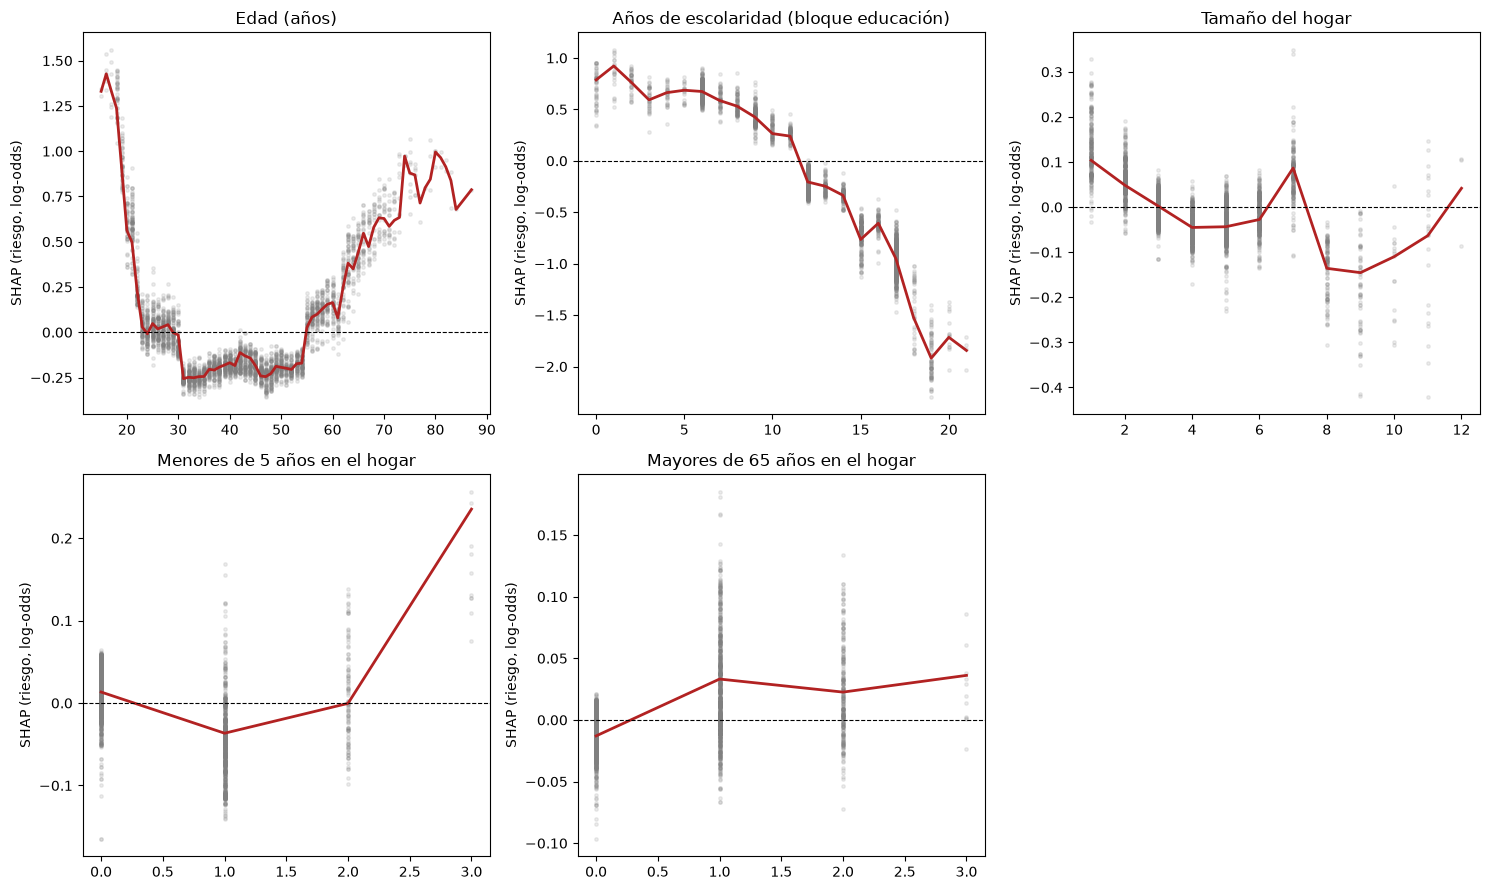

Edad:
t
15-24    0.481
25-34   -0.079
35-44   -0.174
45-54   -0.204
55-64    0.186
65+      0.625
dtype: float64

Escolaridad (bloque educación):
t
0-6      0.689
7-9      0.482
10-12   -0.150
13-15   -0.492
16+     -1.030
dtype: float64


In [32]:
import matplotlib.pyplot as plt

paneles = [
    ("p03", "p03", "Edad (años)"),
    ("anios_esc", "Bloque educación", "Años de escolaridad (bloque educación)"),
    ("tam_hogar", "tam_hogar", "Tamaño del hogar"),
    ("menores5", "menores5", "Menores de 5 años en el hogar"),
    ("mayores65", "mayores65", "Mayores de 65 años en el hogar"),
]

fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
ejes = ejes.ravel()

for ax, (col_x, col_shap, titulo) in zip(ejes, paneles):
    x = X_test[col_x].values
    s = shap_var[col_shap].values
    ax.scatter(x, s, s=6, alpha=0.15, color="gray")
    d = pd.DataFrame({"x": x, "sw": s * w_arr, "w": w_arr}).groupby("x")[["sw", "w"]].sum()
    ax.plot(d.index, d["sw"] / d["w"], color="firebrick", linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(titulo)
    ax.set_ylabel("SHAP (riesgo, log-odds)")

ejes[-1].axis("off")
plt.tight_layout()
plt.savefig("shap_numericas.png", dpi=300)
plt.show()

# Resumen por tramos (ponderado)
def resumen(x, s, cortes, nombres):
    t = pd.cut(x, cortes, labels=nombres, right=False)
    d = (pd.DataFrame({"t": t, "sw": s * w_arr, "w": w_arr})
         .groupby("t", observed=True)[["sw", "w"]].sum())
    return (d["sw"] / d["w"]).round(3)

print("Edad:")
print(resumen(X_test["p03"].values, shap_var["p03"].values,
              [15, 25, 35, 45, 55, 65, 120],
              ["15-24", "25-34", "35-44", "45-54", "55-64", "65+"]))

print("\nEscolaridad (bloque educación):")
print(resumen(X_test["anios_esc"].values, shap_var["Bloque educación"].values,
              [0, 7, 10, 13, 16, 30],
              ["0-6", "7-9", "10-12", "13-15", "16+"]))

In [33]:
sexo = np.where(base_test["p02"].values == 2, "Mujer", "Hombre")
n5 = np.minimum(X_test["menores5"].values, 2)   # 0, 1, 2 = "2 o más"

t = pd.DataFrame({
    "Sexo": sexo,
    "Menores5": n5,
    "sw_n5": shap_var["menores5"].values * w_arr,
    "sw_mujer": shap_var["mujer"].values * w_arr,
    "w": w_arr,
    "Registros": 1,
})

g = t.groupby(["Sexo", "Menores5"])[["sw_n5", "sw_mujer", "w", "Registros"]].sum()
g["SHAP menores5"] = (g["sw_n5"] / g["w"]).round(3)
g["SHAP mujer"] = (g["sw_mujer"] / g["w"]).round(3)

print(g[["Registros", "SHAP menores5", "SHAP mujer"]])

                 Registros  SHAP menores5  SHAP mujer
Sexo   Menores5                                      
Hombre 0              1825          0.015      -0.201
       1               377         -0.044      -0.236
       2                73          0.036      -0.217
Mujer  0              1163          0.011       0.351
       1               230         -0.022       0.415
       2                43          0.029       0.417


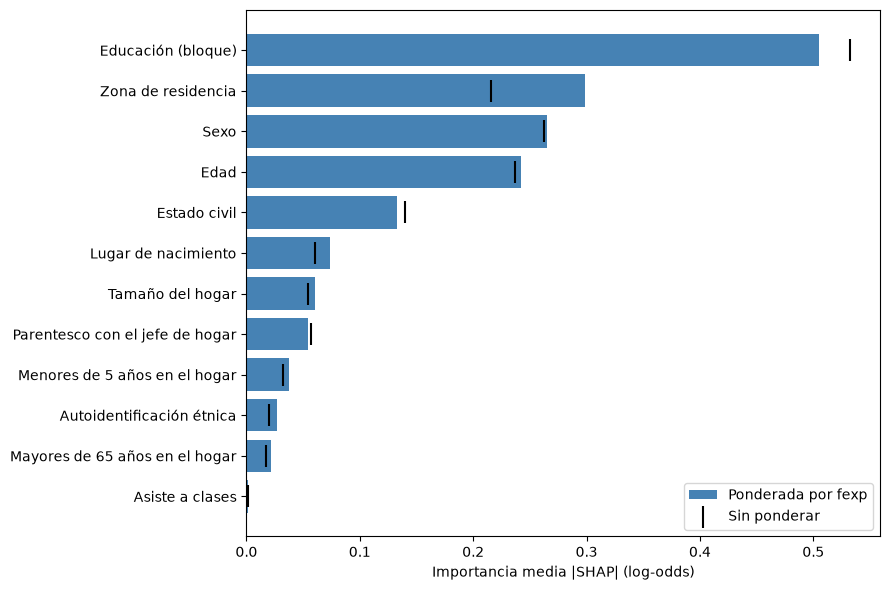

In [34]:
etiquetas_fig = {
    "Bloque educación": "Educación (bloque)",
    "zona_amp": "Zona de residencia",
    "mujer": "Sexo",
    "p03": "Edad",
    "p06": "Estado civil",
    "p15aa": "Lugar de nacimiento",
    "tam_hogar": "Tamaño del hogar",
    "parentesco": "Parentesco con el jefe de hogar",
    "menores5": "Menores de 5 años en el hogar",
    "etnia": "Autoidentificación étnica",
    "mayores65": "Mayores de 65 años en el hogar",
    "asiste_clases": "Asiste a clases",
}

fig_imp = importancia.loc[list(etiquetas_fig)].sort_values("Ponderada")
y = np.arange(len(fig_imp))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y, fig_imp["Ponderada"], color="steelblue", label="Ponderada por fexp")
ax.scatter(fig_imp["Sin ponderar"], y, color="black", marker="|", s=250,
           zorder=3, label="Sin ponderar")
ax.set_yticks(y)
ax.set_yticklabels([etiquetas_fig[v] for v in fig_imp.index])
ax.set_xlabel("Importancia media |SHAP| (log-odds)")
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="lower right")
plt.tight_layout()
plt.savefig("shap_importancia_global.png", dpi=300)
plt.show()


Persona A: riesgo = 0.875 | en el decil superior general: True
                                 Característica   SHAP
Educación (bloque)               Básica, 6 años  0.681
Zona de residencia                  Resto rural  0.321
Sexo                                     Hombre -0.091
Edad                                    64 años  0.265
Estado civil                          Soltero/a  0.133
Lugar de nacimiento              En esta ciudad  0.059
Tamaño del hogar                              1  0.065
Parentesco con el jefe de hogar            Jefe -0.040
Menores de 5 años en el hogar                 0  0.026
Autoidentificación étnica              Montuvio  0.202
Mayores de 65 años en el hogar                0 -0.026
Asiste a clases                              No -0.000


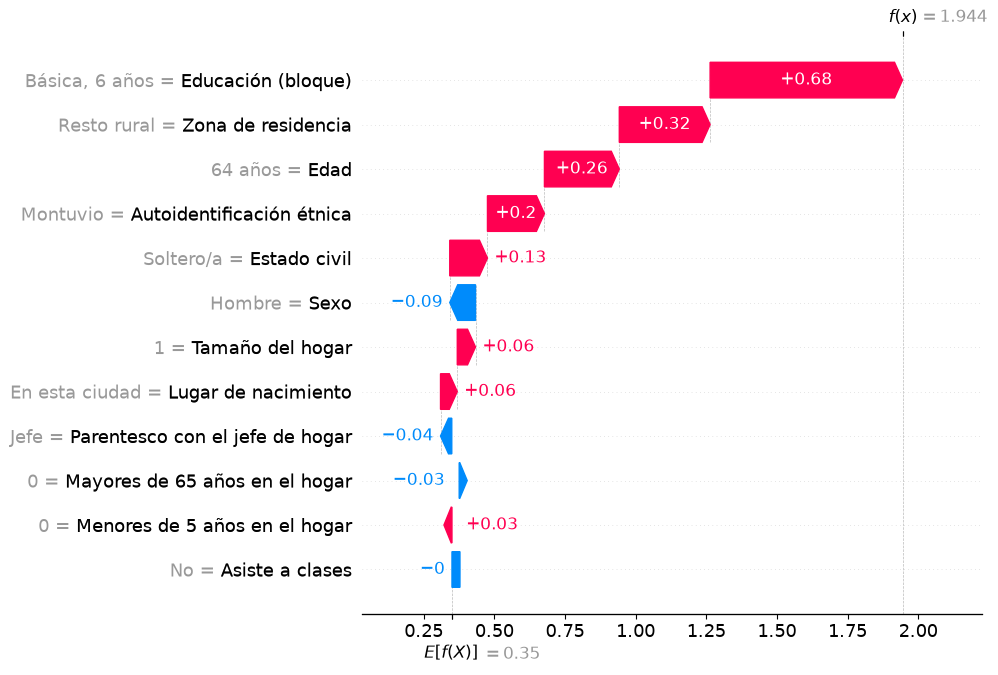


Persona B: riesgo = 0.448 | en el decil superior general: False
                                         Característica   SHAP
Educación (bloque)                       Básica, 6 años  0.705
Zona de residencia                          Conurbación -0.235
Sexo                                             Hombre -0.265
Edad                                            35 años -0.324
Estado civil                                   Casado/a -0.154
Lugar de nacimiento              En otro lugar del país -0.110
Tamaño del hogar                                      3  0.020
Parentesco con el jefe de hogar                    Jefe -0.065
Menores de 5 años en el hogar                         1 -0.056
Autoidentificación étnica                         Otros -0.043
Mayores de 65 años en el hogar                        0 -0.030
Asiste a clases                                      No -0.000


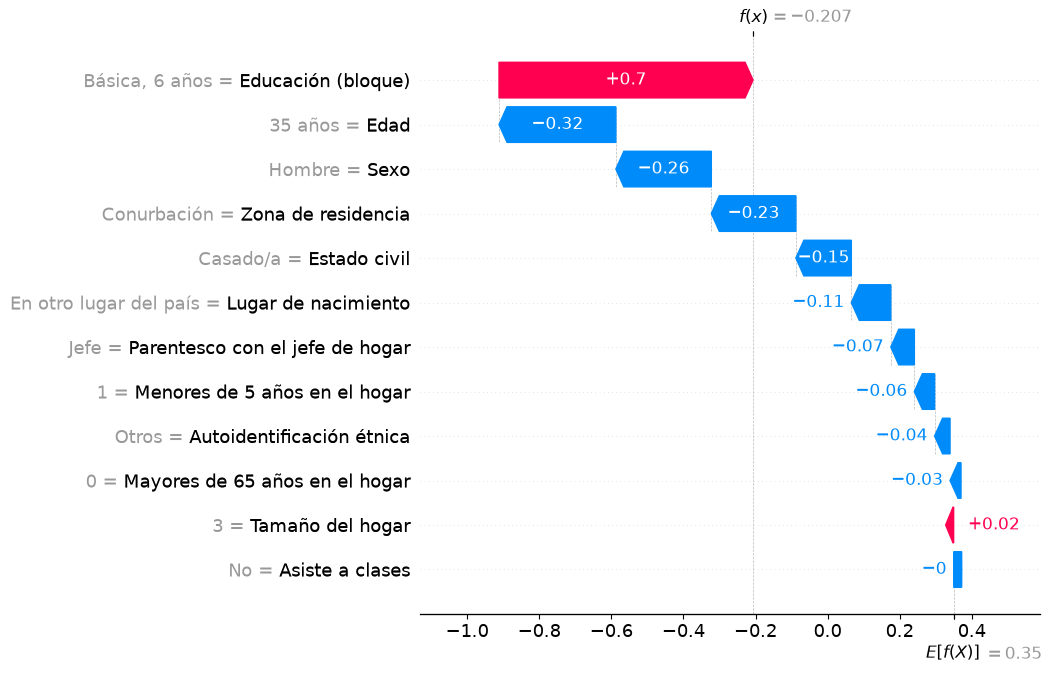

In [35]:
# 1. Elegir a las dos personas (solo por su riesgo, entre las de Básica)
pos_bas = np.where(educ_test == "Básica")[0]
orden_b = pos_bas[np.argsort(riesgo_xgb[pos_bas])]          # de menor a mayor riesgo
acum_b = np.cumsum(w_arr[orden_b]) / w_arr[orden_b].sum()   # percentil ponderado
pos_B = orden_b[np.searchsorted(acum_b, 0.10)]
pos_A = orden_b[np.searchsorted(acum_b, 0.90)]

# 2. Características legibles de cada persona
codigos = {
    "p02": {1: "Hombre", 2: "Mujer"},
    "p07": {1: "Sí", 2: "No"},
    "p06": {1: "Casado/a", 2: "Separado/a", 3: "Divorciado/a", 4: "Viudo/a",
            5: "Unión libre", 6: "Soltero/a"},
    "p15aa": {1: "En esta ciudad", 2: "En otro lugar del país", 3: "En otro país"},
}

def caracteristicas(pos):
    f = base_test.iloc[pos]
    return {
        "Bloque educación": f"{f['instruccion']}, {int(f['anios_esc'])} años",
        "zona_amp": f["zona_amp"],
        "mujer": codigos["p02"].get(f["p02"], f["p02"]),
        "p03": f"{int(f['p03'])} años",
        "p06": codigos["p06"].get(f["p06"], f["p06"]),
        "p15aa": codigos["p15aa"].get(f["p15aa"], f["p15aa"]),
        "tam_hogar": int(f["tam_hogar"]),
        "parentesco": f["parentesco"],
        "menores5": int(f["menores5"]),
        "etnia": f["etnia"],
        "mayores65": int(f["mayores65"]),
        "asiste_clases": codigos["p07"].get(f["p07"], f["p07"]),
    }

# 3. Tabla y cascada de cada persona
grupos = list(etiquetas_fig)

for letra, pos in [("A", pos_A), ("B", pos_B)]:
    car = caracteristicas(pos)
    valores = shap_var.iloc[pos][grupos].values

    print(f"\nPersona {letra}: riesgo = {riesgo_xgb[pos]:.3f} | "
          f"en el decil superior general: {d_xgb[pos]}")
    print(pd.DataFrame({"Característica": [car[g] for g in grupos],
                        "SHAP": valores.round(3)},
                       index=[etiquetas_fig[g] for g in grupos]))

    exp = shap.Explanation(
        values=valores,
        base_values=base_riesgo,
        data=np.array([car[g] for g in grupos], dtype=object),
        feature_names=[etiquetas_fig[g] for g in grupos],
    )
    shap.plots.waterfall(exp, max_display=13, show=False)
    plt.savefig(f"shap_cascada_{letra}.png", dpi=300, bbox_inches="tight")
    plt.show()

## 9. Exportación para R

In [36]:
X_todo = pd.concat([X_train, X_test]).sort_index().astype(float)
base = pd.read_pickle("base_modelado.pkl")
para_r = X_todo.join(base[["y", "upm", "estrato", "fexp"]])
para_r.to_csv("base_logistica_r.csv", index=False)
print(para_r.shape)
print(para_r[["y", "upm", "estrato", "fexp"]].isna().sum())

(19525, 42)
y          0
upm        0
estrato    0
fexp       0
dtype: int64


## 10. Sensibilidad sin etnia

In [37]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
import numpy as np

base_mod = pd.read_pickle("base_modelado.pkl")
w_train = base_mod.loc[X_train.index, "fexp"]
w_train_n = w_train / w_train.mean()
w_test = base_mod.loc[X_test.index, "fexp"]

cols_sin = [c for c in X_train.columns if not c.startswith("etnia_")]

param = dict(max_depth=6, n_estimators=330, learning_rate=0.0114, min_child_weight=4,
             subsample=0.61, colsample_bytree=0.66, random_state=42)

resultados = {}
for nombre, cols in [("con_etnia", list(X_train.columns)), ("sin_etnia", cols_sin)]:
    m = XGBClassifier(**param)
    m.fit(X_train[cols], y_train, sample_weight=w_train_n)
    riesgo = 1 - m.predict_proba(X_test[cols])[:, 1]
    y_r = 1 - y_test
    resultados[nombre] = {"columnas": len(cols),
                          "AUC": roc_auc_score(y_r, riesgo, sample_weight=w_test),
                          "decil": precision_decil(y_r, riesgo, w_test)}

pd.DataFrame(resultados).T.to_csv("sensibilidad_etnia.csv")
pd.DataFrame(resultados).T.round(4)

,columnas,AUC,decil
con_etnia,38.0,0.7667,0.9235
sin_etnia,35.0,0.7648,0.9312


## 11. Logística con edad²

In [38]:
import joblib
from sklearn.base import clone
from sklearn.metrics import accuracy_score

log_base = joblib.load("logistica_final.joblib")
print(log_base)

X_train2 = X_train.assign(edad2=X_train["p03"] ** 2)
X_test2 = X_test.assign(edad2=X_test["p03"] ** 2)

def ajustar(modelo, X, y, w):
    if hasattr(modelo, "steps"):
        return modelo.fit(X, y, **{f"{modelo.steps[-1][0]}__sample_weight": w})
    return modelo.fit(X, y, sample_weight=w)

res_log = {}
for nombre, (Xtr, Xte) in [("log_lineal", (X_train, X_test)), ("log_edad2", (X_train2, X_test2))]:
    m = ajustar(clone(log_base), Xtr, y_train, w_train_n)
    riesgo = 1 - m.predict_proba(Xte)[:, 1]
    res_log[nombre] = {"AUC": roc_auc_score(1 - y_test, riesgo, sample_weight=w_test),
                       "decil": precision_decil(1 - y_test, riesgo, w_test)}
    res_log[nombre] = {"AUC": roc_auc_score(1 - y_test, riesgo, sample_weight=w_test),
                       "decil": precision_decil(1 - y_test, riesgo, w_test),
                       "exactitud": accuracy_score(1 - y_test, (riesgo >= 0.5).astype(int), sample_weight=w_test)}

pd.DataFrame(res_log).T.round(4)

LogisticRegression(C=1000000.0, max_iter=5000)


,AUC,decil,exactitud
log_lineal,0.7506,0.9401,0.7009
log_edad2,0.7643,0.9225,0.6950


In [39]:
riesgos = {}
m_xgb = XGBClassifier(**param).fit(X_train, y_train, sample_weight=w_train_n)
riesgos["XGBoost"] = 1 - m_xgb.predict_proba(X_test)[:, 1]
m_lin = ajustar(clone(log_base), X_train, y_train, w_train_n)
riesgos["Log_lineal"] = 1 - m_lin.predict_proba(X_test)[:, 1]
m_e2 = ajustar(clone(log_base), X_train2, y_train, w_train_n)
riesgos["Log_edad2"] = 1 - m_e2.predict_proba(X_test2)[:, 1]

grupo = base_mod.loc[X_test.index, "instruccion"].values
y_r = (1 - y_test).values
w_t = w_test.values

filas = []
for g in ["Básica", "Media/Bachillerato", "Superior con título"]:
    sel = grupo == g
    fila = {"grupo": g, "registros": sel.sum()}
    for nombre, r in riesgos.items():
        fila[f"AUC_{nombre}"] = roc_auc_score(y_r[sel], r[sel], sample_weight=w_t[sel])
        fila[f"decil_{nombre}"] = precision_decil(y_r[sel], r[sel], w_t[sel])
    filas.append(fila)

pd.DataFrame(filas).set_index("grupo").round(3)

,registros,AUC_XGBoost,decil_XGBoost,AUC_Log_lineal,decil_Log_lineal,AUC_Log_edad2,decil_Log_edad2
grupo,,,,,,,
Básica,964,0.711,0.954,0.664,0.947,0.672,0.918
Media/Bachillerato,1564,0.705,0.852,0.708,0.809,0.736,0.922
Superior con título,803,0.709,0.766,0.610,0.478,0.653,0.469


In [40]:
upm_test = base_mod.loc[X_test.index, "upm"].values
upms = np.unique(upm_test)
pos_por_upm = {u: np.where(upm_test == u)[0] for u in upms}
r_x, r_e2 = riesgos["XGBoost"], riesgos["Log_edad2"]

rng = np.random.default_rng(42)
grupos = ["Básica", "Media/Bachillerato", "Superior con título", "Total"]
registros = []
for b in range(1000):
    muestra = rng.choice(upms, size=len(upms), replace=True)
    idx = np.concatenate([pos_por_upm[u] for u in muestra])
    for g in grupos:
        s = idx if g == "Total" else idx[grupo[idx] == g]
        yy, ww = y_r[s], w_t[s]
        registros.append({"rep": b, "grupo": g,
            "dif_AUC": roc_auc_score(yy, r_x[s], sample_weight=ww) - roc_auc_score(yy, r_e2[s], sample_weight=ww),
            "dif_decil": precision_decil(yy, r_x[s], ww) - precision_decil(yy, r_e2[s], ww)})

boot = pd.DataFrame(registros)
boot.to_csv("bootstrap_xgb_vs_edad2.csv", index=False)

resumen = boot.groupby("grupo").agg(
    AUC_media=("dif_AUC", "mean"),
    AUC_inf=("dif_AUC", lambda x: x.quantile(0.025)),
    AUC_sup=("dif_AUC", lambda x: x.quantile(0.975)),
    AUC_gana_xgb=("dif_AUC", lambda x: (x > 0).mean()),
    decil_media=("dif_decil", "mean"),
    decil_inf=("dif_decil", lambda x: x.quantile(0.025)),
    decil_sup=("dif_decil", lambda x: x.quantile(0.975)),
    decil_gana_xgb=("dif_decil", lambda x: (x > 0).mean()))
resumen.round(3)

,AUC_media,AUC_inf,AUC_sup,AUC_gana_xgb,decil_media,decil_inf,decil_sup,decil_gana_xgb
grupo,,,,,,,,
Básica,0.037,0.014,0.061,0.996,0.032,-0.033,0.110,0.845
Media/Bachillerato,-0.029,-0.074,0.011,0.102,-0.042,-0.151,0.090,0.209
Superior con título,0.051,0.010,0.094,0.993,0.209,0.011,0.382,0.978
Total,0.003,-0.014,0.019,0.625,0.001,-0.041,0.045,0.542


In [41]:
joblib.dump(m_e2, "logistica_edad2.joblib")
pd.DataFrame(res_log).T.to_csv("comparacion_logistica_edad2.csv")
pd.DataFrame(filas).set_index("grupo").to_csv("desempeno_por_grupo_edad2.csv")
resumen.to_csv("resumen_bootstrap_xgb_vs_edad2.csv")

## 12. Figura de resultados

1     0.923
2     0.849
3     0.796
4     0.663
5     0.575
6     0.552
7     0.545
8     0.443
9     0.277
10    0.196
dtype: float64
Prevalencia de base: 0.583


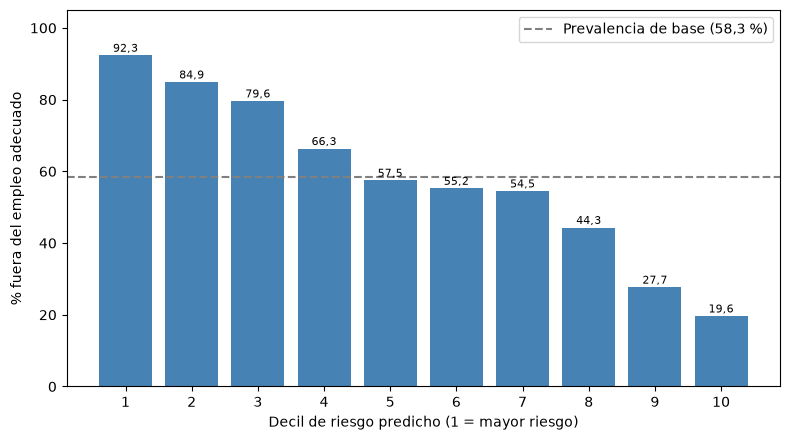

In [42]:
# Precisión por decil de riesgo (XGBoost); deciles formados por pesos (fexp)
r = np.asarray(riesgo_xgb)
yr = np.asarray(y_riesgo)
w = np.asarray(w_test)

orden_d = np.argsort(-r)
w_ord = w[orden_d]
inicio = (np.cumsum(w_ord) - w_ord) / w_ord.sum()   # dónde empieza cada persona en la población
decil = np.empty(len(r), dtype=int)
decil[orden_d] = np.floor(inicio * 10).astype(int) + 1   # 1 = mayor riesgo

prec = pd.Series({d: np.average(yr[decil == d], weights=w[decil == d]) for d in range(1, 11)})
print(prec.round(3))
print("Prevalencia de base:", round(prevalencia, 3))
prec.round(3).to_csv("precision_por_decil.csv", header=["precision"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(prec.index, prec.values * 100, color="steelblue")
ax.axhline(prevalencia * 100, color="gray", linestyle="--",
           label=f"Prevalencia de base ({prevalencia * 100:.1f} %)".replace(".", ","))
for d, v in prec.items():
    ax.text(d, v * 100 + 1, f"{v * 100:.1f}".replace(".", ","), ha="center", fontsize=8)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil de riesgo predicho (1 = mayor riesgo)")
ax.set_ylabel("% fuera del empleo adecuado")
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.savefig("F6_precision_por_decil.png", dpi=300)
plt.show()

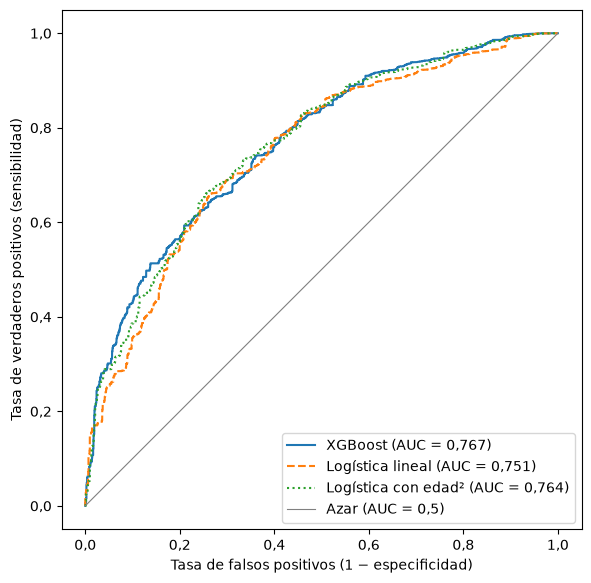

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score

nombres_roc = {"XGBoost": "XGBoost", "Log_lineal": "Logística lineal", "Log_edad2": "Logística con edad²"}
estilos = {"XGBoost": "-", "Log_lineal": "--", "Log_edad2": ":"}

fig, ax = plt.subplots(figsize=(6, 6))
for clave, riesgo in riesgos.items():
    fpr, tpr, _ = roc_curve(y_r, riesgo, sample_weight=w_t)
    auc = roc_auc_score(y_r, riesgo, sample_weight=w_t)
    ax.plot(fpr, tpr, linestyle=estilos[clave], linewidth=1.5,
            label=f"{nombres_roc[clave]} (AUC = {auc:.3f})".replace(".", ","))
ax.plot([0, 1], [0, 1], color="gray", linewidth=0.8, label="Azar (AUC = 0,5)")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.legend(loc="lower right")
ax.set_aspect("equal")
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:.1f}".replace(".", ","))
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.1f}".replace(".", ","))
plt.tight_layout()
plt.savefig("ROC_modelos.png", dpi=300)
plt.show()

                                 Predicho: Con empleo adecuado  \
Real: Con empleo adecuado                                 24.8   
Real: Fuera del empleo adecuado                           13.7   

                                 Predicho: Fuera del empleo adecuado  
Real: Con empleo adecuado                                       16.9  
Real: Fuera del empleo adecuado                                 44.6  
Precision: 0.726 | Recall: 0.765


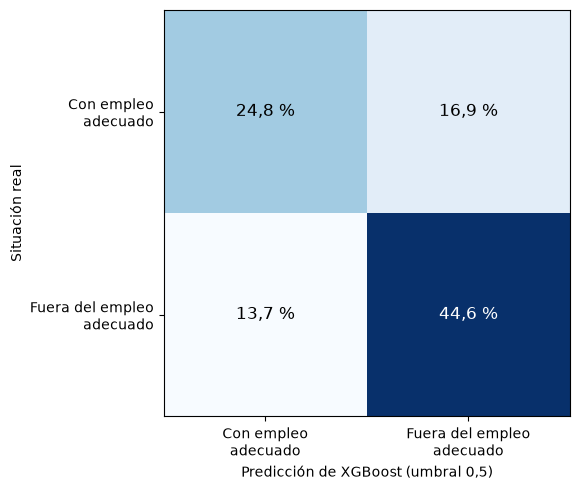

In [44]:
from sklearn.metrics import confusion_matrix

# Matriz de confusión de XGBoost con umbral 0,5, ponderada por fexp (% de la población)
pred_xgb = (riesgo_xgb >= 0.5).astype(int)
cm = confusion_matrix(y_riesgo, pred_xgb, sample_weight=w_test, normalize="all") * 100

etiquetas_cm = ["Con empleo adecuado", "Fuera del empleo adecuado"]
tabla_cm = pd.DataFrame(cm, index=["Real: " + e for e in etiquetas_cm],
                        columns=["Predicho: " + e for e in etiquetas_cm])
print(tabla_cm.round(1))
tabla_cm.round(2).to_csv("matriz_confusion_xgb.csv", encoding="utf-8-sig")

# Control: deben coincidir con metricas_prueba.csv
vp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
print("Precision:", round(vp / (vp + fp), 3), "| Recall:", round(vp / (vp + fn), 3))

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:.1f} %".replace(".", ","), ha="center", va="center",
                fontsize=12, color="white" if cm[i, j] > 30 else "black")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Con empleo\nadecuado", "Fuera del empleo\nadecuado"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Con empleo\nadecuado", "Fuera del empleo\nadecuado"])
ax.set_xlabel("Predicción de XGBoost (umbral 0,5)")
ax.set_ylabel("Situación real")
plt.tight_layout()
plt.savefig("matriz_confusion_xgb.png", dpi=300)
plt.show()